In [47]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [25]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [26]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [27]:
print(f'df.shape: {df.shape}')
print('Columns with string data type: ' + ', '.join(list(df.dtypes[df.dtypes == 'string'].index)))
print('Columns with integer data type: ' + ', '.join(list(df.dtypes[df.dtypes == 'int64'].index)))


df.shape: (5000, 9)
Columns with string data type: lead_source, industry, employment_status, location
Columns with integer data type: number_of_courses_viewed, interaction_count, converted


In [28]:
df.columns
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [33]:
for column in df.columns:
    print(f"{column}: {df[column].isnull().sum()} missing values")


lead_source: 0 missing values
industry: 0 missing values
employment_status: 0 missing values
location: 0 missing values
annual_income: 0 missing values
number_of_courses_viewed: 0 missing values
interaction_count: 0 missing values
lead_score: 0 missing values
converted: 0 missing values


In [31]:
for column in df.columns:
    if df[column].dtypes == 'string':
        df.fillna({column: 'NA'}, inplace=True)
    else:
        df.fillna({column: 0.0}, inplace=True)

In [32]:
df.tail()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1
4999,referral,technology,employed,europe,81355.0,6,11,0.99,1


In [34]:
# Question 1
df['industry'].mode()

0    technology
Name: industry, dtype: str

In [35]:
for i in df.columns:
    print(i, df[i].dtypes)

lead_source str
industry str
employment_status str
location str
annual_income float64
number_of_courses_viewed int64
interaction_count int64
lead_score float64
converted int64


In [36]:
df_numeric = df[['annual_income','lead_score','number_of_courses_viewed','interaction_count','converted']].corr()
df_numeric

,annual_income,lead_score,number_of_courses_viewed,interaction_count,converted
annual_income,1.000000,0.229496,0.161300,0.122842,0.189652
lead_score,0.229496,1.000000,0.757204,0.915746,0.483246
number_of_courses_viewed,0.161300,0.757204,1.000000,0.721609,0.395038
interaction_count,0.122842,0.915746,0.721609,1.000000,0.448624
converted,0.189652,0.483246,0.395038,0.448624,1.000000


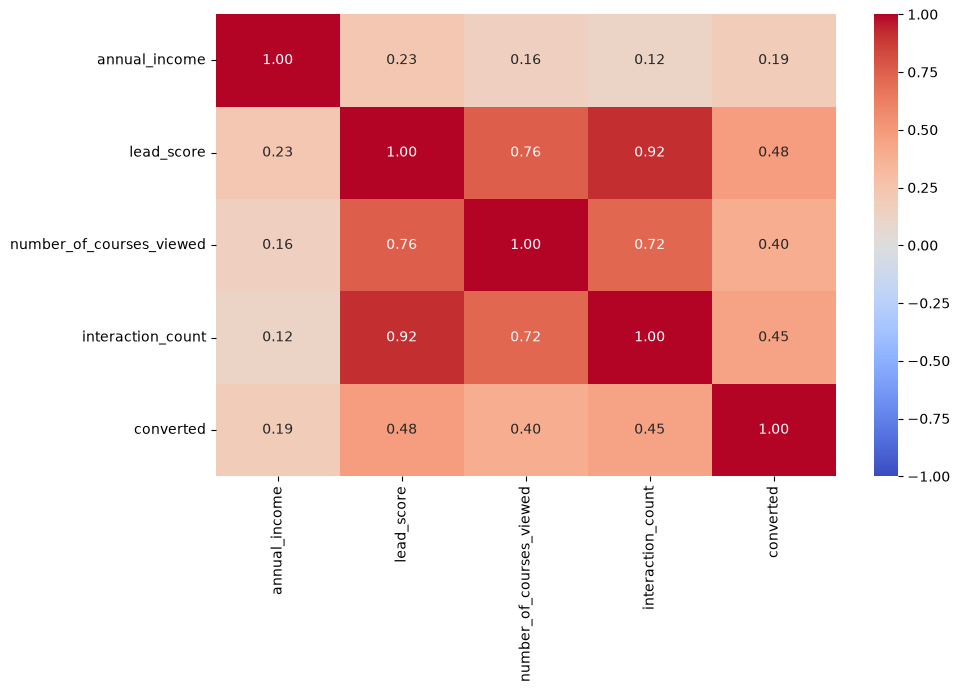

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_numeric, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.show()
plt.show() 

In [38]:
y = df['converted']
y.head()

0    1
1    1
2    1
3    0
4    1
Name: converted, dtype: int64

In [39]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [40]:
categorical = []
for i in df.columns:
    if df[i].dtypes == 'str':
        categorical.append(i)
    print(i, df[i].dtypes)

print("Categorical columns:", categorical)

lead_source str
industry str
employment_status str
location str
annual_income float64
number_of_courses_viewed int64
interaction_count int64
lead_score float64
converted int64
Categorical columns: ['lead_source', 'industry', 'employment_status', 'location']


In [ ]:
# Question 3
from sklearn.metrics import mutual_info_score

def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.converted)



In [50]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

lead_source          0.034761
employment_status    0.020313
industry             0.002898
location             0.001050
dtype: float64

In [58]:
df_train.head(5)
y_train[:5]

array([1, 0, 1, 0, 1])

In [59]:
# Question 4

import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

# 결측치 처리
df_train[categorical] = df_train[categorical].fillna('NA')
df_val[categorical] = df_val[categorical].fillna('NA')
df_train[numerical] = df_train[numerical].fillna(0.0)
df_val[numerical] = df_val[numerical].fillna(0.0)

# one-hot encoding (train에서만 fit)
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = ohe.fit_transform(df_train[categorical])
X_val_cat = ohe.transform(df_val[categorical])

# numerical + categorical 결합
X_train = np.hstack([df_train[numerical].values, X_train_cat])
X_val = np.hstack([df_val[numerical].values, X_val_cat])

# 모델 학습
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

In [60]:
from sklearn.metrics import accuracy_score

y_pred_label = (y_pred >= 0.5).astype(int)
accuracy = accuracy_score(y_val, y_pred_label)
print(round(accuracy, 2))

0.65


In [61]:
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

def train_and_eval(cat_cols, num_cols, C=1.0):
    parts_train, parts_val = [], []
    if cat_cols:
        ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        parts_train.append(ohe.fit_transform(df_train[cat_cols]))
        parts_val.append(ohe.transform(df_val[cat_cols]))
    if num_cols:
        parts_train.append(df_train[num_cols].values)
        parts_val.append(df_val[num_cols].values)

    X_tr = np.hstack(parts_train)
    X_va = np.hstack(parts_val)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_tr, y_train)
    return accuracy_score(y_val, model.predict(X_va))

In [62]:
# Question 5
all_features = categorical + numerical
base_acc = train_and_eval(categorical, numerical)  # 반올림 없이

for f in all_features:
    cat = [c for c in categorical if c != f]
    num = [n for n in numerical if n != f]
    acc = train_and_eval(cat, num)
    print(f"{f:28s} acc={acc:.6f}  diff={base_acc - acc:+.6f}")

lead_source                  acc=0.642000  diff=+0.003000
industry                     acc=0.645000  diff=+0.000000
employment_status            acc=0.645000  diff=+0.000000
location                     acc=0.645000  diff=+0.000000
annual_income                acc=0.724000  diff=-0.079000
number_of_courses_viewed     acc=0.643000  diff=+0.002000
interaction_count            acc=0.601000  diff=+0.044000
lead_score                   acc=0.644000  diff=+0.001000


In [63]:
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    acc = train_and_eval(categorical, numerical, C=C)
    print(f"C={C:<10} acc={round(acc, 3)}")

C=1e-06      acc=0.598
C=1e-05      acc=0.598
C=0.0001     acc=0.613
C=0.001      acc=0.645
